In [ ]:
# import pandas as pd

# file_path = '/content/spotify_songs.csv'
# df = pd.read_csv(file_path)

In [ ]:
# !pip install pyvis
# !pip install colab

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import re
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import pairwise_distances
from sklearn.manifold import TSNE
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
file_path = '/content/drive/MyDrive/spotify_songs.csv'
df = pd.read_csv(file_path)

In [ ]:
orig=df.copy(deep=True)
orig

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.102000,0.000000,0.0653,0.5180,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.072400,0.004210,0.3570,0.6930,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.079400,0.000023,0.1100,0.6130,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.028700,0.000009,0.2040,0.2770,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.080300,0.000000,0.0833,0.7250,123.976,189052
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32828,7bxnKAamR3snQ1VGLuVfC1,City Of Lights - Official Radio Edit,Lush & Simon,42,2azRoBBWEEEYhqV6sb7JrT,City Of Lights (Vocal Mix),2014-04-28,♥ EDM LOVE 2020,6jI1gFr6ANFtT8MmTvA2Ux,edm,...,2,-1.814,1,0.0936,0.076600,0.000000,0.0668,0.2100,128.170,204375
32829,5Aevni09Em4575077nkWHz,Closer - Sultan & Ned Shepard Remix,Tegan and Sara,20,6kD6KLxj7s8eCE3ABvAyf5,Closer Remixed,2013-03-08,♥ EDM LOVE 2020,6jI1gFr6ANFtT8MmTvA2Ux,edm,...,0,-4.462,1,0.0420,0.001710,0.004270,0.3750,0.4000,128.041,353120
32830,7ImMqPP3Q1yfUHvsdn7wEo,Sweet Surrender - Radio Edit,Starkillers,14,0ltWNSY9JgxoIZO4VzuCa6,Sweet Surrender (Radio Edit),2014-04-21,♥ EDM LOVE 2020,6jI1gFr6ANFtT8MmTvA2Ux,edm,...,6,-4.899,0,0.0481,0.108000,0.000001,0.1500,0.4360,127.989,210112
32831,2m69mhnfQ1Oq6lGtXuYhgX,Only For You - Maor Levi Remix,Mat Zo,15,1fGrOkHnHJcStl14zNx8Jy,Only For You (Remixes),2014-01-01,♥ EDM LOVE 2020,6jI1gFr6ANFtT8MmTvA2Ux,edm,...,2,-3.361,1,0.1090,0.007920,0.127000,0.3430,0.3080,128.008,367432


In [ ]:
df.drop_duplicates(subset=['track_id'], inplace=True)
df.dropna(inplace=True)
df.drop_duplicates(subset=['track_name'], inplace=True)

In [ ]:
unique_artists = df['track_artist'].nunique()
print("There are ",unique_artists," unique artists.")

There are  9864  unique artists.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 23449 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  23449 non-null  object 
 1   track_name                23449 non-null  object 
 2   track_artist              23449 non-null  object 
 3   track_popularity          23449 non-null  int64  
 4   track_album_id            23449 non-null  object 
 5   track_album_name          23449 non-null  object 
 6   track_album_release_date  23449 non-null  object 
 7   playlist_name             23449 non-null  object 
 8   playlist_id               23449 non-null  object 
 9   playlist_genre            23449 non-null  object 
 10  playlist_subgenre         23449 non-null  object 
 11  danceability              23449 non-null  float64
 12  energy                    23449 non-null  float64
 13  key                       23449 non-null  int64  
 14  loudness   

In [ ]:
df.describe()

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000,23449.000000
mean,39.744595,0.655214,0.696638,5.374302,-6.848270,0.566677,0.110322,0.181128,0.094075,0.191596,0.511355,121.081191,226107.008444
std,23.407171,0.146209,0.184193,3.617312,3.063606,0.495545,0.104773,0.226139,0.236693,0.157302,0.234759,27.088471,61688.435996
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,23.000000,0.563000,0.578000,2.000000,-8.341000,0.000000,0.041200,0.014800,0.000000,0.092700,0.330000,99.972000,187200.000000
50%,43.000000,0.672000,0.720000,6.000000,-6.285000,1.000000,0.063700,0.082700,0.000019,0.127000,0.513000,122.005000,216133.000000
75%,58.000000,0.762000,0.841000,9.000000,-4.727000,1.000000,0.139000,0.266000,0.006960,0.250000,0.695000,134.781000,254493.000000
max,98.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


In [ ]:
df = df[~df['track_name'].str.contains('remix', case=False)]

In [ ]:
def clean_track_name(track_name):
  cleaned_name = re.sub(r'[^a-zA-Z\s]', '', track_name)
  return cleaned_name.strip()

df['track_name'] = df['track_name'].apply(clean_track_name)

<ipython-input-14-d9b420190a63>:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['track_name'] = df['track_name'].apply(clean_track_name)


In [ ]:

iden=df["track_name"].map(lambda x : x[:11])+df["track_artist"].map(lambda x : "_"+x[:11])
iden.index=df["track_id"]

df["track_name"]=df["track_name"].map(lambda x : x[:11])+df["track_artist"].map(lambda x : "_"+x[:11])

In [ ]:
df.drop_duplicates(subset=['track_name'], inplace=True)

In [ ]:
# prompt: lable encode playlist_genre

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['playlist_genre']  = le.fit_transform(df['playlist_genre'] )
df

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
12,6e0CvGZf7CouOpYF8toXHC,Body On My_Loud Luxury,Loud Luxury,67,2R66I0nzp3NnuUlzIGWQ5P,Body On My,2019-03-29,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,2,...,1,-4.675,1,0.0463,0.039900,0.000000,0.3740,0.6870,121.985,192507
41,6oJ6le65B3SEqPwMRNXWjY,Higher Love_Kygo,Kygo,87,4wquJImu8RtyEuDtIAsfcE,Higher Love,2019-06-28,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,2,...,8,-7.159,1,0.0324,0.015400,0.000006,0.1010,0.4040,103.952,228267
42,2tilX6FUl0IwFgiOYjuc6V,Unlove You_Armin van B,Armin van Buuren,62,6k63cIUizpLu0h5hhIg8LG,Unlove You,2019-10-18,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,2,...,3,-3.660,0,0.0597,0.030300,0.000033,0.1430,0.6630,116.892,150160
43,3yNZ5r3LKfdmjoS3gkhUCT,bad guy wit_Billie Eili,Billie Eilish,83,6lMlX68jJrx67hiCqdiDvW,bad guy (with Justin Bieber),2019-07-11,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,2,...,0,-11.265,1,0.2950,0.252000,0.330000,0.1170,0.6800,135.055,194840
57,1ppOGANOzMT01Cxh9jx4hN,Cool Kids_Olympis,Olympis,67,1ZmJJdNN2BAnVqoiU4xtZe,Cool Kids,2019-11-01,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,2,...,8,-11.297,1,0.0511,0.415000,0.000031,0.1300,0.1190,126.100,139048
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32825,2EpS5TgdngSISM63rhBsnK,Booyah Rad_Showtek,Showtek,47,0Dix8CfvtZEHUyJGnmPnaB,Booyah,2013-01-01,♥ EDM LOVE 2020,6jI1gFr6ANFtT8MmTvA2Ux,0,...,11,-3.050,1,0.0626,0.045300,0.000013,0.2250,0.1950,128.012,215295
32827,0aBDrRTgDCwWbcOnEIp7DJ,Many Ways _Ferry Corst,Ferry Corsten feat. Jenny Wahlstrom,27,59XOfNjuYZB6feC6QUzS3e,Many Ways,2013,♥ EDM LOVE 2020,6jI1gFr6ANFtT8MmTvA2Ux,0,...,5,-8.367,1,0.0365,0.026600,0.000000,0.5720,0.2880,128.001,196993
32828,7bxnKAamR3snQ1VGLuVfC1,City Of Lig_Lush & Simo,Lush & Simon,42,2azRoBBWEEEYhqV6sb7JrT,City Of Lights (Vocal Mix),2014-04-28,♥ EDM LOVE 2020,6jI1gFr6ANFtT8MmTvA2Ux,0,...,2,-1.814,1,0.0936,0.076600,0.000000,0.0668,0.2100,128.170,204375
32830,7ImMqPP3Q1yfUHvsdn7wEo,Sweet Surre_Starkillers,Starkillers,14,0ltWNSY9JgxoIZO4VzuCa6,Sweet Surrender (Radio Edit),2014-04-21,♥ EDM LOVE 2020,6jI1gFr6ANFtT8MmTvA2Ux,0,...,6,-4.899,0,0.0481,0.108000,0.000001,0.1500,0.4360,127.989,210112


In [ ]:
new_df = pd.Series()
new_df = df.set_index('track_id')['playlist_genre']
print(new_df.head())

track_id
6e0CvGZf7CouOpYF8toXHC    2
6oJ6le65B3SEqPwMRNXWjY    2
2tilX6FUl0IwFgiOYjuc6V    2
3yNZ5r3LKfdmjoS3gkhUCT    2
1ppOGANOzMT01Cxh9jx4hN    2
Name: playlist_genre, dtype: int64


In [ ]:
processed_df=df.copy(deep=True)

In [ ]:
cols_to_drop = ["track_name","track_album_id","track_album_name","track_album_release_date","playlist_name","playlist_id","playlist_genre","playlist_subgenre","duration_ms","key","mode","track_popularity"]
df.drop(columns=cols_to_drop, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21222 entries, 12 to 32832
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          21222 non-null  object 
 1   track_artist      21222 non-null  object 
 2   danceability      21222 non-null  float64
 3   energy            21222 non-null  float64
 4   loudness          21222 non-null  float64
 5   speechiness       21222 non-null  float64
 6   acousticness      21222 non-null  float64
 7   instrumentalness  21222 non-null  float64
 8   liveness          21222 non-null  float64
 9   valence           21222 non-null  float64
 10  tempo             21222 non-null  float64
dtypes: float64(9), object(2)
memory usage: 1.9+ MB


In [ ]:
df.reset_index(drop=True, inplace=True)

In [ ]:
numeric_cols = df.select_dtypes(include=['number']).columns
scaler = MinMaxScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

le = LabelEncoder()
df['track_artist'] = le.fit_transform(df['track_artist'])

df.describe()

,track_artist,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,21222.000000,21222.000000,21222.000000,21222.000000,21222.000000,21222.000000,21222.000000,21222.000000,21222.000000,21222.000000
mean,4709.567571,0.666711,0.689957,0.827803,0.121609,0.188943,0.095637,0.192192,0.519136,0.505348
std,2740.565801,0.150768,0.186678,0.064898,0.115613,0.232253,0.240538,0.157999,0.237375,0.115314
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2314.000000,0.570846,0.567924,0.796141,0.044662,0.015996,0.000000,0.093662,0.335015,0.413578
50%,4668.000000,0.683996,0.711950,0.839689,0.069608,0.088732,0.000016,0.127767,0.522704,0.508334
75%,7063.750000,0.777778,0.836971,0.872886,0.154684,0.281690,0.006348,0.248491,0.704339,0.565686
max,9459.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
df.to_csv('spotify_songs_cleaned.csv', index=False)

In [ ]:
tsne = TSNE(n_components=2, random_state=1)  # Adjust perplexity if needed
tsne_results = tsne.fit_transform(df[numeric_cols])
plt.figure(figsize=(10, 8))
plt.scatter(tsne_results[:, 0], tsne_results[:, 1], alpha=0.3,s=4)


plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE Visualization of Spotify Songs")
plt.show()

In [ ]:

# Use the original dataframe 'orig' for genre information
plt.figure(figsize=(10, 8))
plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=[new_df[i] for i in df["track_id"]], alpha=0.3, s=4,cmap="hsv") # Use 'playlist_genre' from 'orig'
plt.colorbar(label='Genre') # Add a colorbar to show genre mapping


plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE Visualization of Spotify Songs (Colored by Genre)")
plt.show()


In [ ]:
# tsne_3d = TSNE(n_components=3, random_state=1)
# tsne_results_3d = tsne_3d.fit_transform(df[numeric_cols])

# fig = plt.figure(figsize=(10, 8))
# ax = fig.add_subplot(111, projection='3d')
# ax.scatter(tsne_results_3d[:, 0], tsne_results_3d[:, 1], tsne_results_3d[:, 2], alpha=0.3, s=4)
# ax.set_xlabel("t-SNE Component 1")
# ax.set_ylabel("t-SNE Component 2")
# ax.set_zlabel("t-SNE Component 3")
# ax.set_title("3D t-SNE Visualization of Spotify Songs")
# plt.show()


In [ ]:
distance_matrix = pairwise_distances(df.drop(columns=['track_id', 'track_artist']), metric='manhattan')

In [ ]:
# distance_matrix += pairwise_distances(df[['track_artist']], metric='matching')

In [ ]:
distance_df_combined = pd.DataFrame(distance_matrix, index=df['track_id'], columns=df['track_id'])
distance_df_combined

In [ ]:
# x=distance_df_combined[distance_df_combined.columns[:30]].head(30)
# print(x)
# x.to_csv('spotify_songs_cleaned.csv', index=True)
# from google.colab import files
# files.download('spotify_songs_cleaned.csv')

In [ ]:
# prompt: make a copy of distance_df with only the lowest 7 distances kept for each song

import pandas as pd

def get_lowest_distances(distance_df, n=7):
  new_df = pd.DataFrame()
  for song in distance_df.index:
    #sort the distances for the song
    distances = distance_df.loc[song].sort_values()
    #get the lowest n distances
    lowest_distances = distances[1:n+1]
    #create a temporary dataframe from the lowest n distances
    temp_df = pd.DataFrame({'track_id': song, 'similar_track_id': lowest_distances.index, 'distance': lowest_distances.values})
    new_df = pd.concat([new_df, temp_df], ignore_index=True)
  return new_df

lowest_distance_df = get_lowest_distances(distance_df_combined)


In [ ]:
lowest_distance_df

In [ ]:
# # prompt: make lowest_distance_df into a nxn matrix

# import numpy as np

# # Assuming 'lowest_distance_df' is already defined as in your provided code

# # Create a mapping from track_id to index
# track_id_to_index = {track_id: index for index, track_id in enumerate(df['track_id'])}

# # Create an empty matrix with zeros
# n = len(df['track_id'])
# distance_matrix1 = np.zeros((n, n))

# # Populate the matrix
# for index, row in lowest_distance_df.iterrows():
#   track_id_1 = row['track_id']
#   track_id_2 = row['similar_track_id']
#   distance = row['distance']

#   i = track_id_to_index.get(track_id_1)
#   j = track_id_to_index.get(track_id_2)

#   if i is not None and j is not None:
#     distance_matrix1[i, j] = distance
#     distance_matrix1[j, i] = distance # Assuming the distance is symmetric

# # Now distance_matrix is an NxN matrix representing the distances
# distance_matrix1


In [ ]:
# distance_df_combined = pd.DataFrame(distance_matrix1, index=df['track_id'], columns=df['track_id'])
# distance_df_combined

In [ ]:

import random

def random_walk(start_node, distance_df, num_steps=15):
    visited = [start_node]
    current_node = start_node
    for _ in range(num_steps):
        neighbors = distance_df[distance_df['track_id'] == current_node]['similar_track_id'].tolist()
        # Remove already visited nodes
        available_neighbors = [node for node in neighbors if node not in visited]
        if not available_neighbors:
          print("No more unvisited neighbors. Walk ends here")
          break
        # Select the next node randomly from available neighbors
        current_node = random.choice(available_neighbors)
        visited.append(current_node)
    return visited


In [ ]:
def find_closest_songs(start_song_id, num_songs=15):
    current_song = start_song_id
    path = [current_song]

    for _ in range(num_songs - 1):
        closest_songs = distance_df_combined[current_song].sort_values()

        # Exclude already visited songs
        candidates = [song for song in closest_songs.index if song not in path]

        if not candidates:
            break # No more unvisited neighbors

        next_song = candidates[1]
        path.append(next_song)
        current_song = next_song
    return path


def find_closest_song_indices(songs_path):
    indices = []
    for song_id in songs_path:
        index = df.index[df['track_id'] == song_id].tolist()[0]
        indices.append(index)
    return indices


In [ ]:
random_song_index = random.randint(0, len(df) - 1)
start_track = df['track_id'].iloc[random_song_index]



walk = random_walk(start_track, lowest_distance_df)
print("Closest 15 songs:", iden[walk].tolist())
walk_indices = find_closest_song_indices(walk)


closest_songs_path = find_closest_songs(start_track)
print("Closest 15 songs:", iden[closest_songs_path].tolist())
closest_song_indices = find_closest_song_indices(closest_songs_path)



Closest 15 songs: ['The Noise I_Assemblage ', 'Youre All I_The Cars', 'Happy When _The Jesus a', 'Desire_Gene Loves ', 'Fast_Salty Dog', 'Sun Is Dark_Noize Gener', 'Du hast_Rammstein', 'Shattered D_Flowbee', 'Give Me You_Sigala', 'Helium  Rad_Chris Lake', 'Who Am I fe_Enzo Ingros', 'Are You Lis_DubVision', 'We Got That_Yves V', 'Sugar feat _Robin Schul', 'Where Do Yo_Shaun Frank', 'Blame It On_Josh Thomps']
Closest 15 songs: ['The Noise I_Assemblage ', 'Desire_Gene Loves ', 'Heads Will _Yeah Yeah Y', 'Fast_Salty Dog', 'Happy When _The Jesus a', 'Map of the _Muse', 'Hawk Eyes_The Kicks', 'Zero Gravit_Alveole', 'TimeBomb_All Time Lo', 'Cousins_TXYLOR', 'Umaaraw Umu_Rivermaya', 'Deathwish_Red Sun Ris', 'Kathleen_Catfish and', 'My Body_Young the G', 'Gone Are Th_Grand Slam']


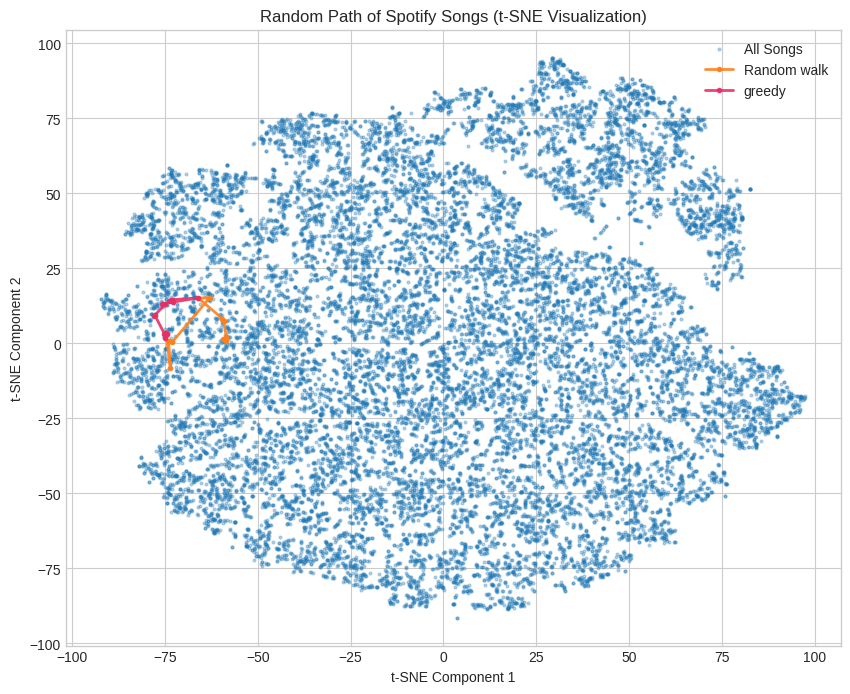

In [ ]:
path1_indices = walk_indices
path1_coordinates = tsne_results[path1_indices]

path2_indices = closest_song_indices
path2_coordinates = tsne_results[path2_indices]


plt.figure(figsize=(10, 8))
plt.scatter(tsne_results[:, 0], tsne_results[:, 1], alpha=0.3, s=4, label='All Songs')  # All songs


plt.plot(path1_coordinates[:, 0], path1_coordinates[:, 1], marker='.', color=(1,.5,0.1,0.9), linestyle='-', linewidth=2, label='Random walk')

# for i, idx in enumerate(path_indices):
#   plt.annotate(iden[df.iloc[idx]['track_id']], (path_coordinates[i, 0], path_coordinates[i, 1]), fontsize=2)


plt.plot(path2_coordinates[:, 0], path2_coordinates[:, 1], marker='.', color=(.9,.19,0.4,0.9), linestyle='-', linewidth=2, label='greedy')

# for i, idx in enumerate(path_indices):
#   plt.annotate(iden[df.iloc[idx]['track_id']], (path_coordinates[i, 0], path_coordinates[i, 1]), fontsize=2)


plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("Random Path of Spotify Songs (t-SNE Visualization)")
plt.legend()
plt.show()


In [ ]:
def diversity(path):
    x=distance_df_combined[path].T[path].sum().sum()/14/14
    return x
def drift(path):
    x=distance_df_combined[path[0]].T[path[-1]]
    return x
def distance(path):
    x=sum([distance_df_combined[path[i]][path[i+1]] for i in range(len(path)-1)])/14
    return x

In [ ]:
eval=pd.DataFrame(columns=['walk_drift','walk_diversity','walk_distance','greedy_drift','greedy_diversity','greedy_distance'])

In [ ]:
for i in range(2500):
    random_song_index = random.randint(0, len(df) - 1)
    start_track = df['track_id'].iloc[random_song_index]

    walk = random_walk(start_track, lowest_distance_df)


    closest_songs_path = find_closest_songs(start_track)

    eval.loc[i]=[drift(walk),diversity(walk),distance(walk),drift(closest_songs_path),diversity(closest_songs_path),distance(closest_songs_path)]

No more unvisited neighbors. Walk ends here


In [ ]:
eval.describe()

,walk_drift,walk_diversity,walk_distance,greedy_drift,greedy_diversity,greedy_distance
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,0.807177,0.594650,0.261997,0.774623,0.500394,0.232336
std,0.341034,0.181252,0.070951,0.319563,0.155032,0.064264
min,0.132468,0.073609,0.095219,0.155589,0.229703,0.127912
25%,0.568960,0.466398,0.211509,0.556785,0.394585,0.187020
50%,0.750030,0.570569,0.250332,0.724780,0.475104,0.220873
75%,0.989375,0.680871,0.296021,0.946002,0.577057,0.263357
max,3.498122,2.060363,0.660856,3.103912,1.679966,0.697334


In [ ]:
for i in range(2501,5001):
    random_song_index = random.randint(0, len(df) - 1)
    start_track = df['track_id'].iloc[random_song_index]

    walk = random_walk(start_track, lowest_distance_df)


    closest_songs_path = find_closest_songs(start_track)

    eval.loc[i]=[drift(walk),diversity(walk),distance(walk),drift(closest_songs_path),diversity(closest_songs_path),distance(closest_songs_path)]

No more unvisited neighbors. Walk ends here
No more unvisited neighbors. Walk ends here


In [ ]:
eval.describe()


,walk_drift,walk_diversity,walk_distance,greedy_drift,greedy_diversity,greedy_distance
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,0.811153,0.596399,0.261607,0.771974,0.498793,0.231928
std,0.335294,0.177700,0.070046,0.318595,0.153844,0.063632
min,0.132468,0.073609,0.095219,0.155589,0.225563,0.126468
25%,0.572907,0.468510,0.211300,0.547415,0.391010,0.186583
50%,0.754553,0.574039,0.251087,0.720949,0.473075,0.221207
75%,0.992690,0.687129,0.295652,0.938875,0.576866,0.262696
max,3.498122,2.060363,0.660856,3.103912,1.679966,0.697334


In [ ]:
for i in range(5001,10001):
    random_song_index = random.randint(0, len(df) - 1)
    start_track = df['track_id'].iloc[random_song_index]

    walk = random_walk(start_track, lowest_distance_df)


    closest_songs_path = find_closest_songs(start_track)

    eval.loc[i]=[drift(walk),diversity(walk),distance(walk),drift(closest_songs_path),diversity(closest_songs_path),distance(closest_songs_path)]

No more unvisited neighbors. Walk ends here
No more unvisited neighbors. Walk ends here
No more unvisited neighbors. Walk ends here


In [ ]:
eval.describe()


,walk_drift,walk_diversity,walk_distance,greedy_drift,greedy_diversity,greedy_distance
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,0.810224,0.596006,0.261016,0.769855,0.497601,0.231780
std,0.337607,0.177531,0.069532,0.319042,0.153306,0.063631
min,0.122462,0.073609,0.095219,0.102610,0.223325,0.126468
25%,0.572480,0.469808,0.210454,0.543140,0.391003,0.186468
50%,0.754553,0.571678,0.250994,0.719521,0.472954,0.220918
75%,0.984736,0.688494,0.295263,0.937396,0.574069,0.262344
max,3.669723,2.060363,0.758698,3.315875,1.679966,0.697334


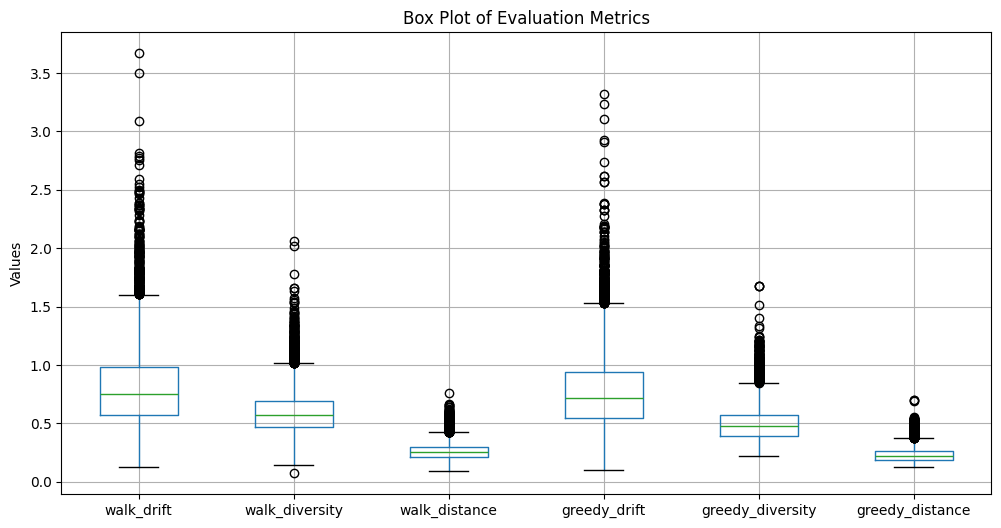

In [ ]:
# prompt: make box plot for eval in a single graph

import matplotlib.pyplot as plt

# Create the box plot
plt.figure(figsize=(12, 6))
eval.boxplot(column=['walk_drift', 'walk_diversity', 'walk_distance', 'greedy_drift', 'greedy_diversity', 'greedy_distance'])
plt.title('Box Plot of Evaluation Metrics')
plt.ylabel('Values')
plt.show()


distance max values: [0.758698 0.697334]
drift max values: [3.669723 3.315875]
diversity max values: [2.060363 1.679966]


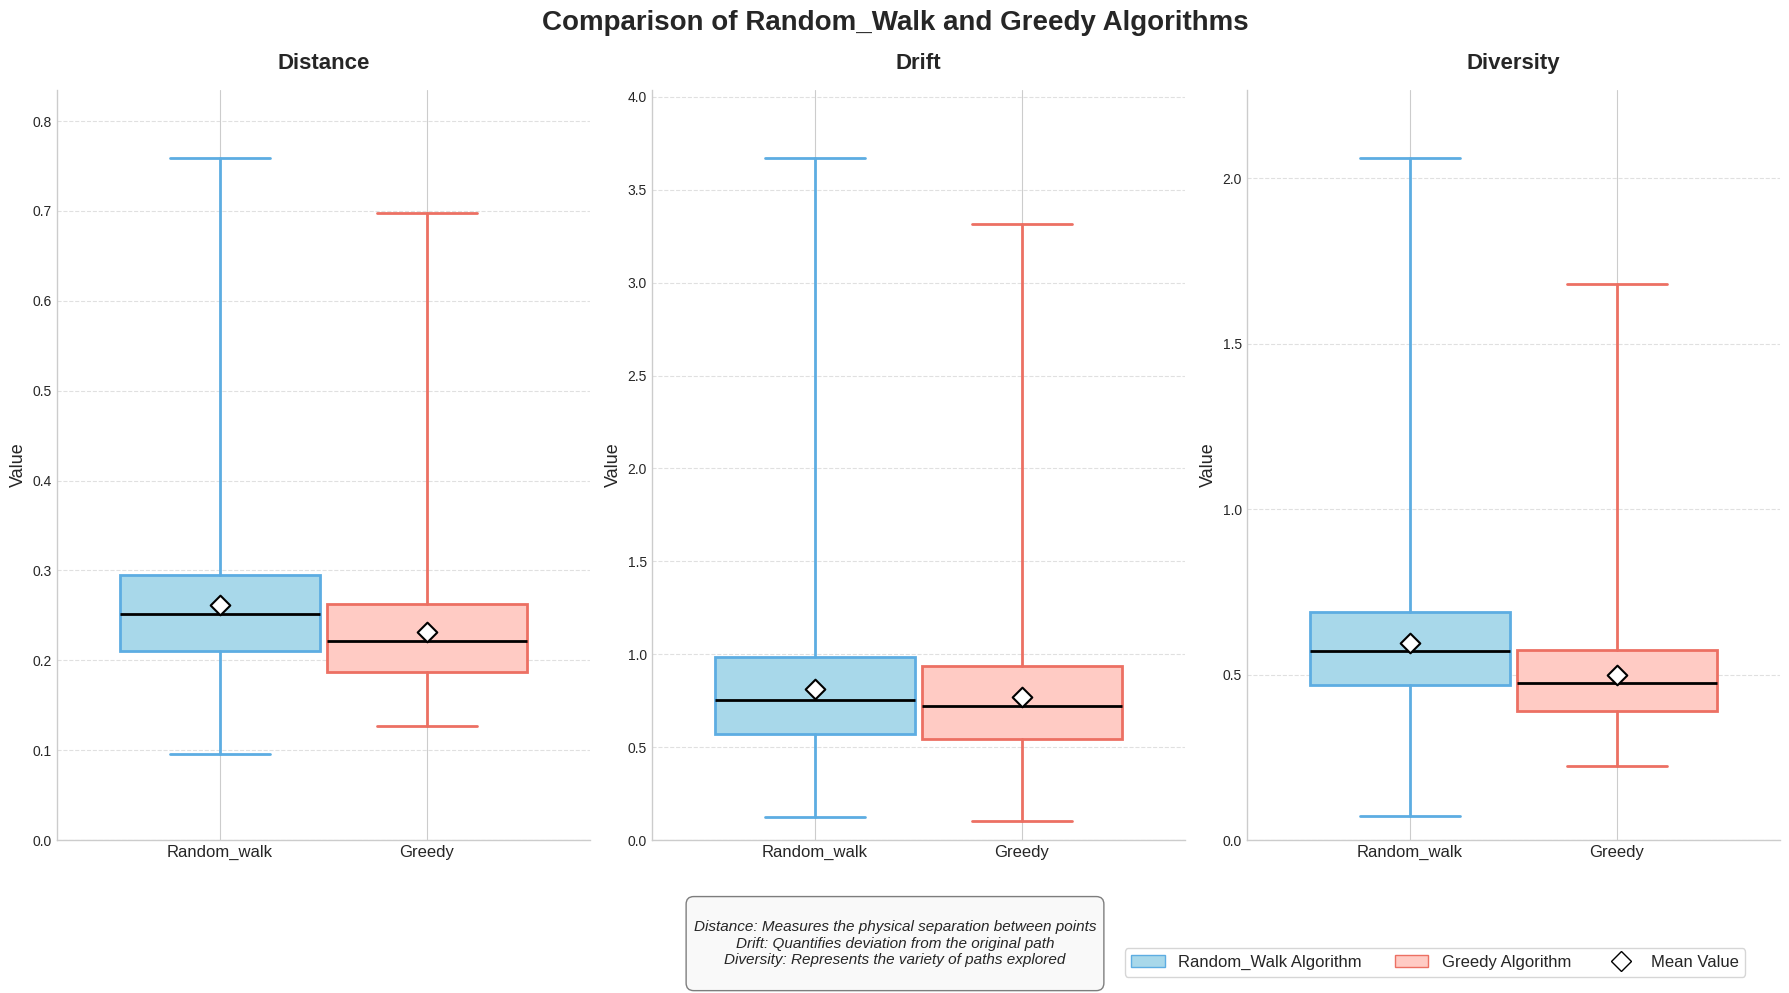

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import MultipleLocator

# Set the seed for reproducibility
np.random.seed(42)

# Set the style
plt.style.use('seaborn-v0_8-whitegrid')
pastel_colors = {
    'Random_walk': '#A8D8EA',  # light blue
    'greedy': '#FFCBC4', # light salmon
    'Random_walk_edge': '#5DADE2', # darker blue
    'greedy_edge': '#EC7063' # darker salmon
}

# Create DataFrame with summary statistics
# This is the key - ensuring we have the full data range
summary_stats = pd.DataFrame({
    'metric': ['Random_walk_drift', 'Random_walk_diversity', 'Random_walk_distance',
               'greedy_drift', 'greedy_diversity', 'greedy_distance'],
    'algorithm': ['Random_walk', 'Random_walk', 'Random_walk', 'greedy', 'greedy', 'greedy'],
    'type': ['drift', 'diversity', 'distance', 'drift', 'diversity', 'distance'],
    'count': [10000] * 6,
    'mean': [0.810224, 0.596006, 0.261016, 0.769855, 0.497601, 0.231780],
    'std': [0.337607, 0.177531, 0.069532, 0.319042, 0.153306, 0.063631],
    'min': [0.122462, 0.073609, 0.095219, 0.102610, 0.223325, 0.126468],
    '25%': [0.572480, 0.469808, 0.210454, 0.543140, 0.391003, 0.186468],
    '50%': [0.754553, 0.571678, 0.250994, 0.719521, 0.472954, 0.220918],
    '75%': [0.984736, 0.688494, 0.295263, 0.937396, 0.574069, 0.262344],
    'max': [3.669723, 2.060363, 0.758698, 3.315875, 1.679966, 0.697334]
})

# Create figure with three subplots
# Adjusting width-to-height ratio to make plots wider
fig, axs = plt.subplots(1, 3, figsize=(18, 10), dpi=100)

# Function to create a boxplot for a specific metric type
def create_aesthetic_boxplot(metric_type, ax):
    # Filter data for the specific metric type
    filtered_data = summary_stats[summary_stats['type'] == metric_type]

    # Prepare data in the format needed for boxplot with full whiskers
    boxplot_data = []
    for _, row in filtered_data.iterrows():
        # Create a five-number summary: [min, 25%, median, 75%, max]
        boxplot_data.append([row['min'], row['25%'], row['50%'], row['75%'], row['max']])

    # Create manual boxplot using matplotlib's primitive
    box_positions = [1.19, 1.81]  # Wider spacing between boxes

    # Create boxplot with EXPLICIT whiskers
    bp = ax.boxplot(
        boxplot_data,
        positions=box_positions,
        patch_artist=True,
        widths=0.6,
        showmeans=False,
        showfliers=False,
        showcaps=True,
        whis=[0, 100],  # Force whiskers to go to min/max
        manage_ticks=True
    )

    # Apply custom colors and styling
    for i, box in enumerate(bp['boxes']):
        algorithm = filtered_data['algorithm'].iloc[i]
        box.set_facecolor(pastel_colors[algorithm])
        box.set_edgecolor(pastel_colors[f"{algorithm}_edge"])
        box.set_linewidth(2)

    # Make whiskers more visible
    for i, whisker in enumerate(bp['whiskers']):
        algorithm = filtered_data['algorithm'].iloc[i//2]
        whisker.set_color(pastel_colors[f"{algorithm}_edge"])
        whisker.set_linewidth(2)
        whisker.set_linestyle('-')  # Solid line

    # Make caps more visible
    for i, cap in enumerate(bp['caps']):
        algorithm = filtered_data['algorithm'].iloc[i//2]
        cap.set_color(pastel_colors[f"{algorithm}_edge"])
        cap.set_linewidth(2)

    # Customize medians
    for i, median in enumerate(bp['medians']):
        median.set_color('black')
        median.set_linewidth(2)

    # Add mean markers
    for i, (_, row) in enumerate(filtered_data.iterrows()):
        ax.scatter(
            box_positions[i],
            row['mean'],
            marker='D',
            s=100,
            color='white',
            edgecolor='black',
            linewidth=1.5,
            zorder=3
        )

    # Set x-axis properties
    ax.set_xlim(.7, 2.3)  # Wider x-axis span
    ax.set_xticks(box_positions)
    ax.set_xticklabels([alg.capitalize() for alg in filtered_data['algorithm']], fontsize=12)

    # Set title and labels
    ax.set_title(f'{metric_type.capitalize()}', fontsize=16, fontweight='bold', pad=15)
    ax.set_ylabel('Value', fontsize=13)

    # Set y-axis limits explicitly to show all data
    if metric_type == 'distance':
        ax.set_ylim(0, filtered_data['max'].max() * 1.1)
    elif metric_type == 'drift':
        ax.set_ylim(0, filtered_data['max'].max() * 1.1)
    elif metric_type == 'diversity':
        ax.set_ylim(0, filtered_data['max'].max() * 1.1)

    # Customize grid
    ax.grid(axis='y', linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Print the max value to verify we're seeing the full range
    print(f"{metric_type} max values: {filtered_data['max'].values}")

    return ax

# Create each subplot with explicit whisker range
create_aesthetic_boxplot('distance', axs[0])
create_aesthetic_boxplot('drift', axs[1])
create_aesthetic_boxplot('diversity', axs[2])

# Add overall title
fig.suptitle('Comparison of Random_Walk and Greedy Algorithms',
             fontsize=20, fontweight='bold', y=0.98)

# Add caption
caption = """
Distance: Measures the physical separation between points
Drift: Quantifies deviation from the original path
Diversity: Represents the variety of paths explored
"""
fig.text(0.5, 0.01, caption, ha='center', fontsize=11, fontstyle='italic',
         bbox=dict(facecolor='#F5F5F5', alpha=0.5, boxstyle='round,pad=0.5'))

# Create legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = [
    Patch(facecolor=pastel_colors['Random_walk'], edgecolor=pastel_colors['Random_walk_edge'],
          label='Random_Walk Algorithm'),
    Patch(facecolor=pastel_colors['greedy'], edgecolor=pastel_colors['greedy_edge'],
          label='Greedy Algorithm'),
    Line2D([0], [0], marker='D', color='w', markerfacecolor='white',
           markeredgecolor='black', markersize=10, label='Mean Value')
]
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.80, 0.05),
           ncol=3, fontsize=12, frameon=True)

# Adjust layout
plt.tight_layout()
plt.subplots_adjust(top=0.9, bottom=0.15)

# Save and show the plot
plt.savefig('algorithm_comparison_fixed_whiskers.png', dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
most_frequent_artists = orig['track_artist'].value_counts().head(40)  # Get top 10
print(most_frequent_artists)


track_artist
Martin Garrix                161
Queen                        136
The Chainsmokers             123
David Guetta                 110
Don Omar                     102
Drake                        100
Dimitri Vegas & Like Mike     93
Calvin Harris                 91
Hardwell                      84
Kygo                          83
Guns N' Roses                 79
The Weeknd                    76
Avicii                        74
J Balvin                      72
Maroon 5                      71
Ed Sheeran                    69
Major Lazer                   67
Logic                         66
Daddy Yankee                  66
Tiësto                        66
2Pac                          65
DJ Snake                      62
Wisin & Yandel                61
Bad Bunny                     61
Post Malone                   59
50 Cent                       57
Khalid                        57
Rihanna                       57
Ozuna                         56
Ariana Grande                 

In [ ]:
print(*processed_df[processed_df['track_artist'] == 'Queen']['track_name'].unique() ,sep="\n")



Dont Stop M_Queen
Radio Ga Ga_Queen
We Are The _Queen
Killer Quee_Queen
Under Press_Queen
We Will Roc_Queen
Keep Yourse_Queen
Doing Alrig_Queen
Great King _Queen
My Fairy Ki_Queen
Liar  Remas_Queen
The Night C_Queen
Modern Time_Queen
Son And Dau_Queen
Jesus  Rema_Queen
Seven Seas _Queen
Procession _Queen
Father To S_Queen
White Queen_Queen
Some Day On_Queen
The Loser I_Queen
Ogre Battle_Queen
The Fairy F_Queen
Nevermore  _Queen
The March O_Queen
Funny How L_Queen
Brighton Ro_Queen
Tenement Fu_Queen
Flick Of Th_Queen
Lily Of The_Queen
Now Im Here_Queen
In The Lap _Queen
Stone Cold _Queen
Dear Friend_Queen
Misfire  Re_Queen
Bring Back _Queen
She Makes M_Queen
Death On Tw_Queen
Lazing On A_Queen
Im In Love _Queen
Youre My Be_Queen
Mix_Queen
Sweet Lady _Queen
Seaside Ren_Queen
The Prophet_Queen
Love Of My _Queen
Good Compan_Queen
Bohemian Rh_Queen
God Save Th_Queen
Tie Your Mo_Queen
You Take My_Queen
Long Away  _Queen
The Million_Queen
You And I  _Queen
Somebody To_Queen
White Man  _Queen


Track ID for 'Life Of The_Shawn Mendes': 7hQJA50XrCWABAu5v6QZ4i
Closest 15 songs_random_walk: ['Dont Stop M_Queen', 'Feels Like _Weezer', 'All About I_Good Times ', 'My Songs Kn_Fall Out Bo', 'Girls Girls_Mötley Crüe', 'Poppin Cham_All Time Lo', 'Ghosts feat_Feenixpawl', 'Who Am I fe_Enzo Ingros', 'Are You Lis_DubVision', 'Righteous D_The Dead Da', 'Gassed Up_Upchurch', 'Love That W_Silience', 'Electric Lo_BØRNS', 'High_Young Risin', 'Whatever Yo_Dasco', 'I Will Foll_Laura Pieri']
Closest 15 songs_greedy: ['Dont Stop M_Queen', 'Pentakill_Neelo', 'Seventeen  _Thomas Gold', 'Careless_Vacation Ma', 'One Foot_WALK THE MO', 'She Hates M_Puddle Of M', 'Swimming In_Passion Pit', 'Half Your A_Joywave', 'White Trash_Black Stone', 'Live To Win_Paul Stanle', 'Together  R_Thomas News', 'The Phoenix_Fall Out Bo', 'Paradise Wh_Within Temp', 'Hate To Say_The Hives', 'Phantom of _Upchurch']


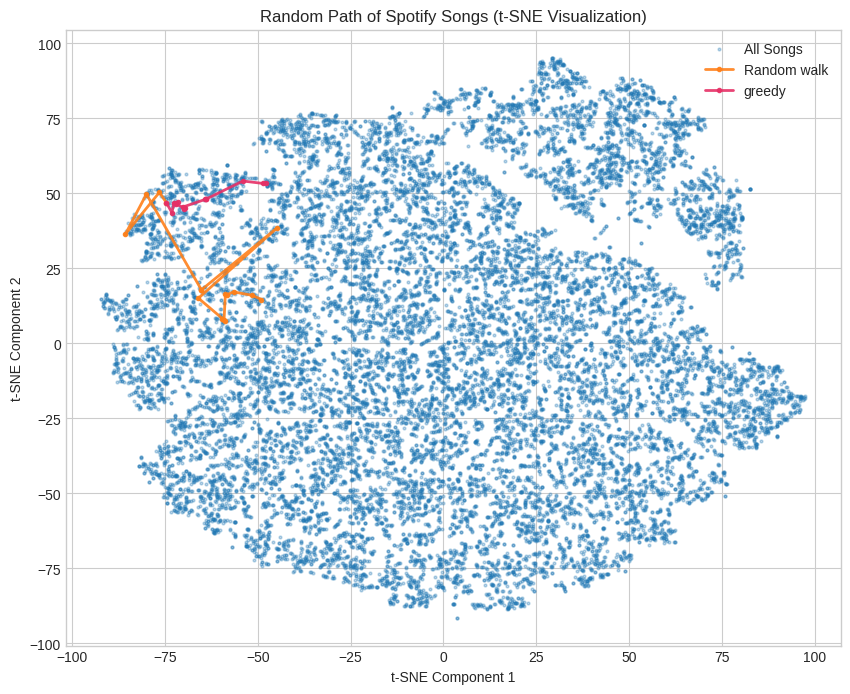

In [ ]:
track_id = processed_df[processed_df['track_artist'] == 'Queen']['track_id'].iloc[0]
print(f"Track ID for 'Life Of The_Shawn Mendes': {track_id}")



start_track = track_id



walk = random_walk(start_track, lowest_distance_df)
print("Closest 15 songs_random_walk:", iden[walk].tolist())
walk_indices = find_closest_song_indices(walk)


closest_songs_path = find_closest_songs(start_track)
print("Closest 15 songs_greedy:", iden[closest_songs_path].tolist())
closest_song_indices = find_closest_song_indices(closest_songs_path)

path1_indices = walk_indices
path1_coordinates = tsne_results[path1_indices]

path2_indices = closest_song_indices
path2_coordinates = tsne_results[path2_indices]


plt.figure(figsize=(10, 8))
plt.scatter(tsne_results[:, 0], tsne_results[:, 1], alpha=0.3, s=4, label='All Songs')  # All songs


plt.plot(path1_coordinates[:, 0], path1_coordinates[:, 1], marker='.', color=(1,.5,0.1,0.9), linestyle='-', linewidth=2, label='Random walk')

# for i, idx in enumerate(path_indices):
#   plt.annotate(iden[df.iloc[idx]['track_id']], (path_coordinates[i, 0], path_coordinates[i, 1]), fontsize=2)


plt.plot(path2_coordinates[:, 0], path2_coordinates[:, 1], marker='.', color=(.9,.19,0.4,0.9), linestyle='-', linewidth=2, label='greedy')

# for i, idx in enumerate(path_indices):
#   plt.annotate(iden[df.iloc[idx]['track_id']], (path_coordinates[i, 0], path_coordinates[i, 1]), fontsize=2)


plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("Random Path of Spotify Songs (t-SNE Visualization)")
plt.legend()
plt.show()



In [ ]:
walk=['Dont Stop M_Queen', 'Feels Like _Weezer', 'All About I_Good Times ', 'My Songs Kn_Fall Out Bo', 'Girls Girls_Mötley Crüe', 'Poppin Cham_All Time Lo', 'Ghosts feat_Feenixpawl', 'Who Am I fe_Enzo Ingros',
                               'Are You Lis_DubVision', 'Righteous D_The Dead Da', 'Gassed Up_Upchurch', 'Love That W_Silience', 'Electric Lo_BØRNS', 'High_Young Risin', 'Whatever Yo_Dasco', 'I Will Foll_Laura Pieri']


greedy=['Dont Stop M_Queen', 'Pentakill_Neelo', 'Seventeen  _Thomas Gold', 'Careless_Vacation Ma', 'One Foot_WALK THE MO', 'She Hates M_Puddle Of M', 'Swimming In_Passion Pit', 'Half Your A_Joywave', 'White Trash_Black Stone',
                          'Live To Win_Paul Stanle', 'Together  R_Thomas News', 'The Phoenix_Fall Out Bo', 'Paradise Wh_Within Temp', 'Hate To Say_The Hives', 'Phantom of _Upchurch']


In [ ]:
x=[iden.index[list(iden.values).index(i)] for i in greedy]
x

['7hQJA50XrCWABAu5v6QZ4i',
 '3vFbJ2n0sNzZG2HCww0BF9',
 '7JMUHcnjYWMGez9qWsgoQc',
 '6H725KQnIbXVkRPrapOTXZ',
 '0iQ77tSa7ncj7zBPtVx6cU',
 '16DhvbuyvJob4Q9GHNYu2n',
 '4jmADw2rRriDjzSruTySZ7',
 '0yTlrnue3pJTJd7h7d43mk',
 '3UWYmWg9j8KVV08ANBqcLB',
 '0sohcbFmi4BhkQTOBf7vOv',
 '3AsUkHdWdQWjT2FgEe8nzY',
 '53AuxddsgPSlqM619nJhSd',
 '7jhYBaGt3WSzYaW6CRrmL2',
 '20j7B6mL9gnNvG3ic6Vwh5',
 '5CJzig6FYq9fs2auN7ODWn']

In [ ]:
greedy

['Dont Stop M_Queen',
 'Pentakill_Neelo',
 'Seventeen  _Thomas Gold',
 'Careless_Vacation Ma',
 'One Foot_WALK THE MO',
 'She Hates M_Puddle Of M',
 'Swimming In_Passion Pit',
 'Half Your A_Joywave',
 'White Trash_Black Stone',
 'Live To Win_Paul Stanle',
 'Together  R_Thomas News',
 'The Phoenix_Fall Out Bo',
 'Paradise Wh_Within Temp',
 'Hate To Say_The Hives',
 'Phantom of _Upchurch']

In [ ]:
[list(processed_df[processed_df['track_id']==i]["track_artist"].values)[0] for i in x]

['Queen',
 'Neelo',
 'Thomas Gold',
 'Vacation Manor',
 'WALK THE MOON',
 'Puddle Of Mudd',
 'Passion Pit',
 'Joywave',
 'Black Stone Cherry',
 'Paul Stanley',
 'Thomas Newson',
 'Fall Out Boy',
 'Within Temptation',
 'The Hives',
 'Upchurch']